# Data Cleaning: Amazon Sales Dataset
**Oasis Infobyte | Data Analytics | Level 1 | Task 3**

**Objective:** Convert the raw, messy Amazon India product dataset into a clean, analysis-ready file and document every decision.

## 1. Load the dataset
The raw file is loaded into `raw`, and all work is done on a copy (`df`) so the original data stays untouched.

In [1]:
import numpy as np
import pandas as pd
pd.options.display.float_format = "{:,.2f}".format

raw = pd.read_csv("amazon.csv")
df = raw.copy()
print(df.shape)D
df.head(3)

(1465, 16)


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...


## 2. Data quality report (before cleaning)
Checking data types, null values, unique counts and duplicates to find problems before fixing anything.

In [2]:
report = pd.DataFrame({"dtype": df.dtypes.astype(str),
                       "nulls": df.isnull().sum(),
                       "unique": df.nunique()})
display(report)
print("Duplicate rows:", df.duplicated().sum())
print("Repeated product_id:", df["product_id"].duplicated().sum())

,dtype,nulls,unique
product_id,str,0,1351
product_name,str,0,1337
category,str,0,211
discounted_price,str,0,550
actual_price,str,0,449
discount_percentage,str,0,92
rating,str,0,28
rating_count,str,2,1143
about_product,str,0,1293
user_id,str,0,1194


Duplicate rows: 0
Repeated product_id: 114


**Issues found:** Price, discount, rating and rating_count are stored as text (₹, commas, %). `rating_count` has 2 missing values. 114 rows repeat a `product_id`. `category` is a pipe-separated hierarchy.

## 3. Save the "before" snapshot
Recording key metrics now so a before vs. after comparison can be made at the end.

In [4]:
num_cols = ["discounted_price", "actual_price",
            "discount_percentage", "rating", "rating_count"]
before = {
    "rows": len(raw),
    "total_nulls": int(raw.isnull().sum().sum()),
    "duplicate_rows": int(raw.duplicated().sum()),
    "duplicate_product_ids": int(raw["product_id"].duplicated().sum()),
    "numeric_cols_correct_dtype": int(sum(
        pd.api.types.is_numeric_dtype(raw[c]) for c in num_cols)),
}
before

{'rows': 1465,
 'total_nulls': 2,
 'duplicate_rows': 0,
 'duplicate_product_ids': 114,
 'numeric_cols_correct_dtype': 0}

## 4. Fix data types (text to numbers)
Removing ₹, commas and % signs, then converting to numbers. `errors="coerce"` turns unparseable values into NaN instead of crashing, so they show up as nulls and get handled in the next step.

In [5]:
def to_number(s):
    return pd.to_numeric(
        s.astype(str).str.replace(r"[₹,%]", "", regex=True).str.strip(),
        errors="coerce")

for col in num_cols:
    df[col] = to_number(df[col])

print(df[num_cols].dtypes)
print(df[num_cols].isnull().sum())

discounted_price       float64
actual_price           float64
discount_percentage      int64
rating                 float64
rating_count           float64
dtype: object
discounted_price       0
actual_price           0
discount_percentage    0
rating                 1
rating_count           2
dtype: int64


## 5. Handle missing values
**Strategy:** median imputation for `rating_count` and `rating`. `rating_count` is highly right-skewed (a few products have very large counts), so the mean would be misleading. Only 3 cells are affected, so imputing keeps the products in the dataset.

In [6]:
df["rating_count"] = df["rating_count"].fillna(df["rating_count"].median())
df["rating"] = df["rating"].fillna(df["rating"].median())
print("Nulls left:", df.isnull().sum().sum())

Nulls left: 0


## 6. Remove duplicates
There are no fully duplicated rows, but the same `product_id` appears multiple times. Product-level analysis needs one row per product, so the first occurrence is kept. 114 rows are removed.

In [7]:
n_before = len(df)
df = df.drop_duplicates(subset="product_id", keep="first").reset_index(drop=True)
print(f"Removed {n_before - len(df)} duplicates -> {len(df)} unique products")

Removed 114 duplicates -> 1351 unique products


In [8]:
for col in ["product_name", "category"]:
    df[col] = df[col].str.strip()

parts = df["category"].str.split("|", expand=True)
df["main_category"] = parts[0].str.replace("&", " & ")
df["sub_category"] = parts[1].str.replace("&", " & ")
df["leaf_category"] = df["category"].str.split("|").str[-1].str.replace("&", " & ")
print(df["main_category"].value_counts())

main_category
Electronics                490
Home & Kitchen             448
Computers & Accessories    375
OfficeProducts              31
MusicalInstruments           2
HomeImprovement              2
Toys & Games                 1
Car & Motorbike              1
Health & PersonalCare        1
Name: count, dtype: int64


## 7. Validate values and add features
Checks: ratings must be 1 to 5, prices must be positive, and the stored discount % must match the one calculated from the prices. Also adding `discount_amount` as a useful new column.

In [9]:
print("Ratings outside 1-5:", ((df["rating"] < 1) | (df["rating"] > 5)).sum())
print("Non-positive prices:", (df["discounted_price"] <= 0).sum())

calc = ((df["actual_price"] - df["discounted_price"])
        / df["actual_price"] * 100).round()
print("Discount mismatches:", ((calc - df["discount_percentage"]).abs() > 1).sum())

df["discount_amount"] = df["actual_price"] - df["discounted_price"]
df["rating_count"] = df["rating_count"].astype(int)

Ratings outside 1-5: 0
Non-positive prices: 0
Discount mismatches: 0


**Result:** All values are valid. No ratings are out of range, no prices are non-positive, and the discount percentages match the prices.

## 8. Outlier detection (IQR method)
Values beyond 1.5 × IQR from the quartiles are flagged as outliers.

In [10]:
rows = []
for col in ["discounted_price", "actual_price", "rating_count", "rating"]:
    q1, q3 = df[col].quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append({"column": col, "lower": lo, "upper": hi,
                 "outliers": n, "outlier_%": n / len(df) * 100})
pd.DataFrame(rows)

,column,lower,upper,outliers,outlier_%
0,discounted_price,"-2,388.50","4,911.50",209,15.47
1,actual_price,"-4,615.00","10,089.00",185,13.69
2,rating_count,"-21,225.00","38,327.00",130,9.62
3,rating,3.30,4.90,19,1.41


**Decision: all outliers are retained.**
- `discounted_price` and `actual_price`: high values are genuine premium products (TVs, laptops), not errors.
- `rating_count`: popular products legitimately have very large counts. A log transform is better than removal for modelling.
- `rating`: low ratings reflect real customer opinion.

## 9. Before vs. after summary

In [11]:
after = {
    "rows": len(df),
    "total_nulls": int(df[num_cols].isnull().sum().sum()),
    "duplicate_rows": int(df.duplicated().sum()),
    "duplicate_product_ids": int(df["product_id"].duplicated().sum()),
    "numeric_cols_correct_dtype": int(sum(
        pd.api.types.is_numeric_dtype(df[c]) for c in num_cols)),
}
pd.DataFrame({"Before": before, "After": after})

,Before,After
rows,1465,1351
total_nulls,2,0
duplicate_rows,0,0
duplicate_product_ids,114,0
numeric_cols_correct_dtype,0,5


## 10. Save the cleaned dataset

In [13]:
df.to_csv("amazon_cleaned.csv", index=False)
print(df.shape)

(1351, 20)


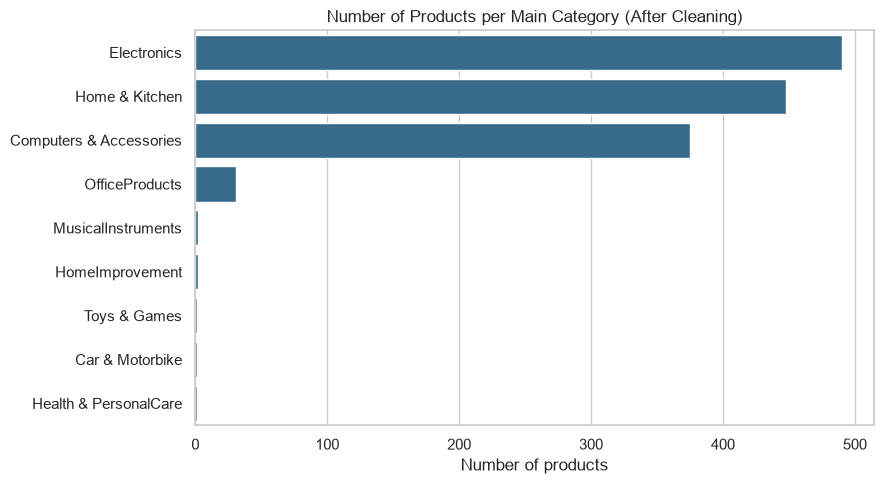

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(9, 5))
order = df["main_category"].value_counts().index
sns.countplot(data=df, y="main_category", order=order, color="#2a6f97")
plt.title("Number of Products per Main Category (After Cleaning)")
plt.xlabel("Number of products")
plt.ylabel("")
plt.tight_layout()
plt.show()

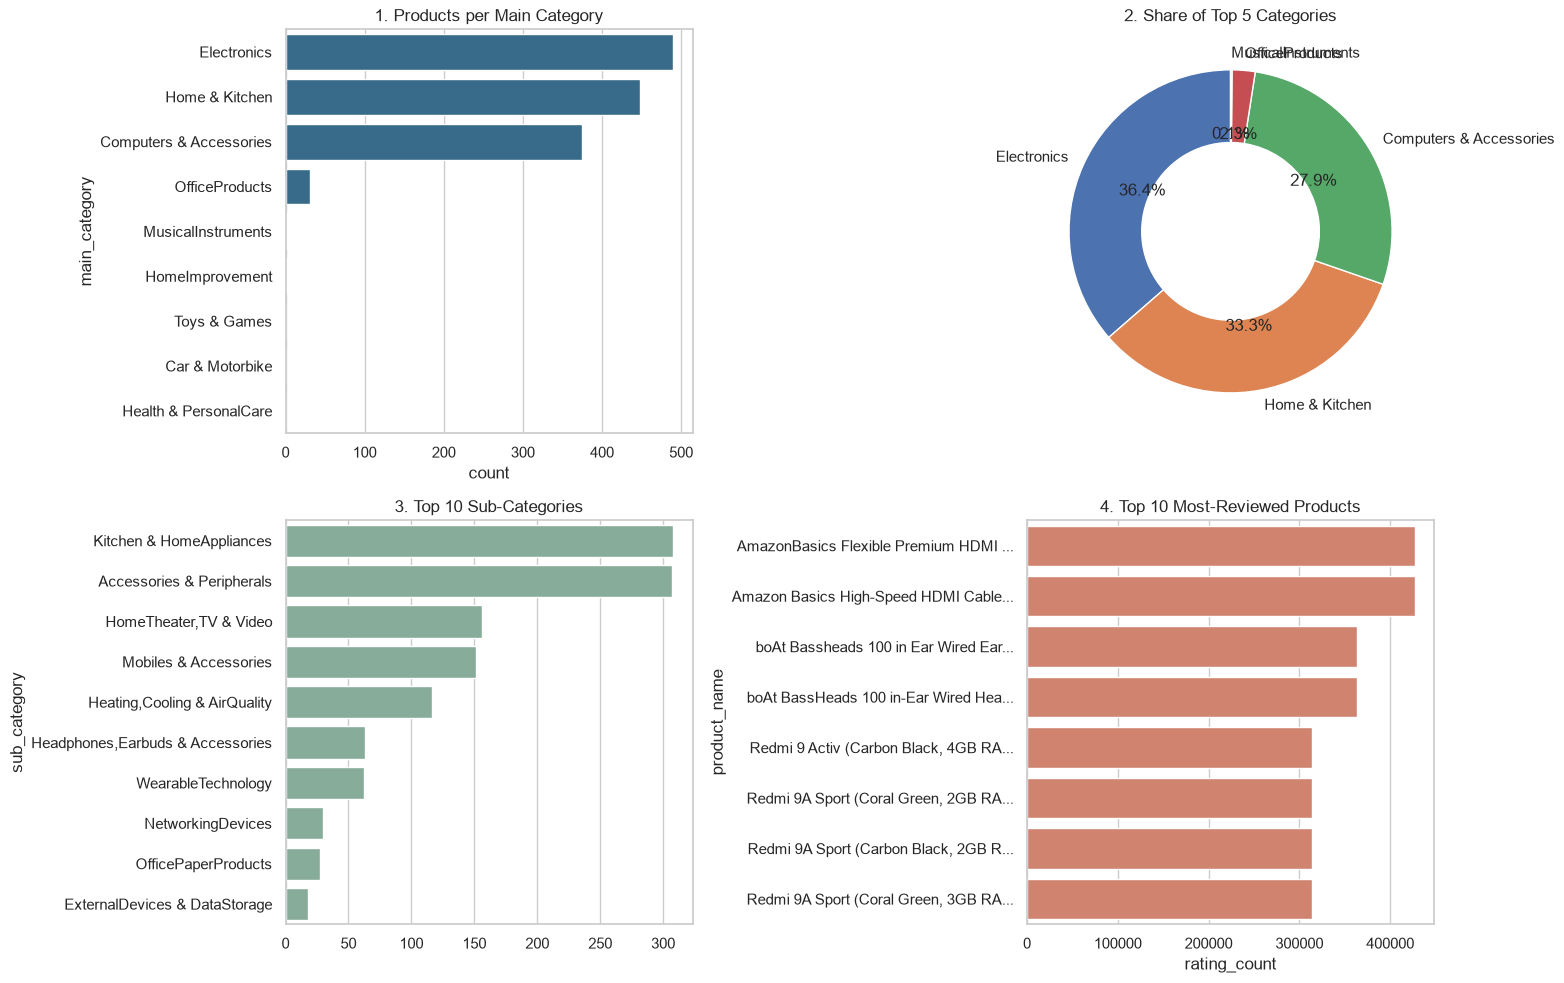

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(2, 2, figsize=(15, 10))
order = df["main_category"].value_counts().index
sns.countplot(data=df, y="main_category", order=order, color="#2a6f97", ax=ax[0, 0])
ax[0, 0].set_title("1. Products per Main Category")

top_main = df["main_category"].value_counts().head(5)
ax[0, 1].pie(top_main, labels=top_main.index, autopct="%1.1f%%",
             startangle=90, wedgeprops={"width": 0.45})
ax[0, 1].set_title("2. Share of Top 5 Categories")

sub = df["sub_category"].value_counts().head(10)
sns.barplot(x=sub.values, y=sub.index, color="#81b29a", ax=ax[1, 0])
ax[1, 0].set_title("3. Top 10 Sub-Categories")

top_prod = df.nlargest(10, "rating_count")[["product_name", "rating_count"]].copy()
top_prod["product_name"] = top_prod["product_name"].str[:35] + "..."
sns.barplot(data=top_prod, x="rating_count", y="product_name",
            color="#e07a5f", ax=ax[1, 1])
ax[1, 1].set_title("4. Top 10 Most-Reviewed Products")
plt.tight_layout(); plt.show()

### Observations: Price
1. **Price distribution:** The log-scale histogram shows most products are low-priced. The median discounted price is about ₹899 while the mean is about ₹3,305, so a few expensive items pull the average up (right-skewed).
2. **Price by category:** Electronics has the widest price range, with its box plot reaching far above the others. Computers & Accessories is the cheapest of the big three (median about ₹399).
3. **Actual vs discounted price:** The scatter plot is almost a straight line (correlation 0.96). Higher-priced products stay higher-priced after discounting, so discount does not change the price ranking.
4. **Average price by category:** Electronics has the highest average discounted price (about ₹6,226), compared with about ₹2,331 for Home & Kitchen. Categories with only 1-2 products, like Car & Motorbike, should be ignored because their averages are not reliable.

**Insight:** Electronics earns the premium prices, while accessories and office items are low-cost.

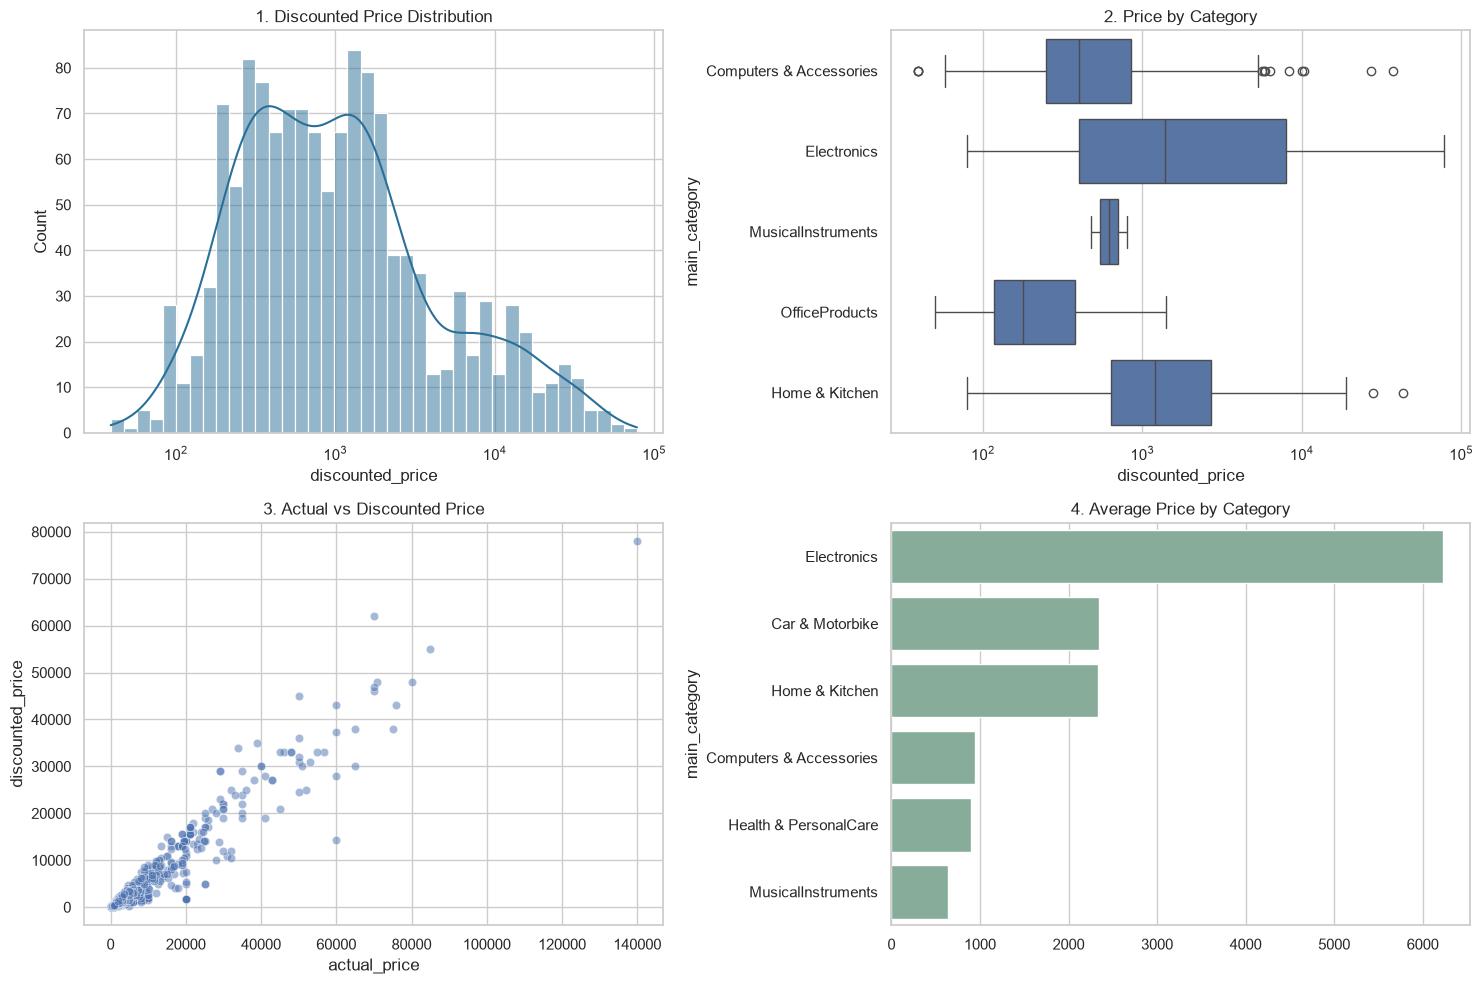

In [16]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(df["discounted_price"], bins=40, log_scale=True, kde=True,
             color="#2a6f97", ax=ax[0, 0])
ax[0, 0].set_title("1. Discounted Price Distribution")

top5 = df["main_category"].value_counts().head(5).index
sns.boxplot(data=df[df["main_category"].isin(top5)], y="main_category",
            x="discounted_price", log_scale=True, ax=ax[0, 1])
ax[0, 1].set_title("2. Price by Category")

sns.scatterplot(data=df, x="actual_price", y="discounted_price",
                alpha=0.5, ax=ax[1, 0])
ax[1, 0].set_title("3. Actual vs Discounted Price")

avg = (df.groupby("main_category")["discounted_price"].mean()
         .sort_values(ascending=False).head(6))
sns.barplot(x=avg.values, y=avg.index, color="#81b29a", ax=ax[1, 1])
ax[1, 1].set_title("4. Average Price by Category")
plt.tight_layout(); plt.show()

### Observations: Price
1. **Price distribution:** The log-scale histogram shows most products are low-priced. The median discounted price is about ₹899 while the mean is about ₹3,305, so a few expensive items pull the average up (right-skewed).
2. **Price by category:** Electronics has the widest price range, with its box plot reaching far above the others. Computers & Accessories is the cheapest of the big three (median about ₹399).
3. **Actual vs discounted price:** The scatter plot is almost a straight line (correlation 0.96). Higher-priced products stay higher-priced after discounting, so discount does not change the price ranking.
4. **Average price by category:** Electronics has the highest average discounted price (about ₹6,226), compared with about ₹2,331 for Home & Kitchen. Categories with only 1-2 products, like Car & Motorbike, should be ignored because their averages are not reliable.

**Insight:** Electronics earns the premium prices, while accessories and office items are low-cost.

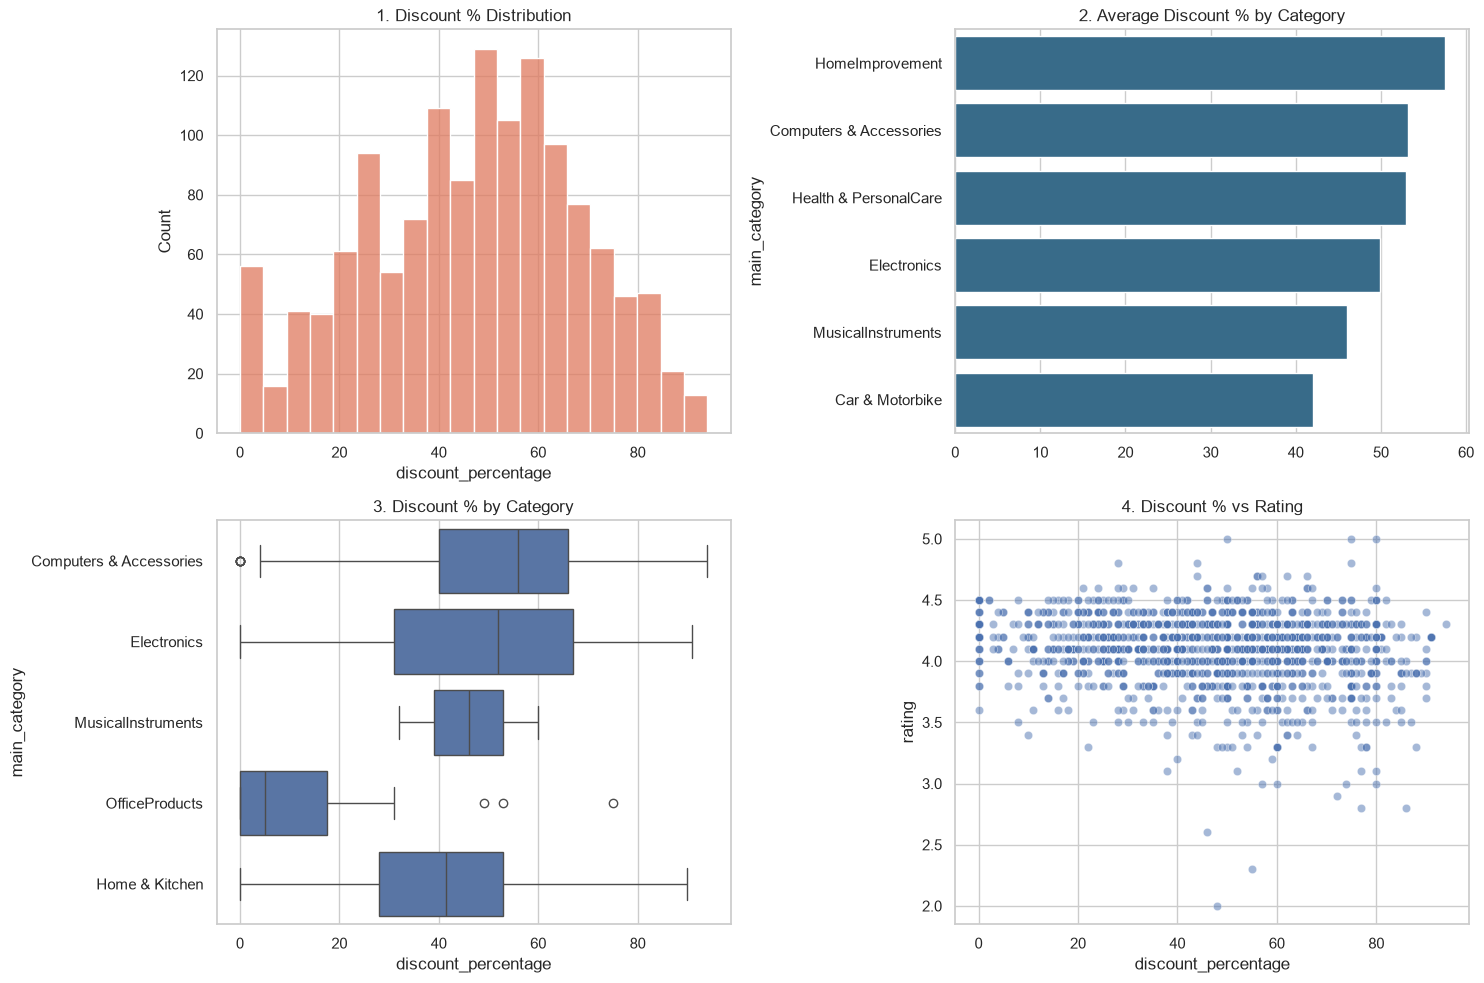

In [17]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(df["discount_percentage"], bins=20, color="#e07a5f", ax=ax[0, 0])
ax[0, 0].set_title("1. Discount % Distribution")

d = (df.groupby("main_category")["discount_percentage"].mean()
       .sort_values(ascending=False).head(6))
sns.barplot(x=d.values, y=d.index, color="#2a6f97", ax=ax[0, 1])
ax[0, 1].set_title("2. Average Discount % by Category")

sns.boxplot(data=df[df["main_category"].isin(top5)], y="main_category",
            x="discount_percentage", ax=ax[1, 0])
ax[1, 0].set_title("3. Discount % by Category")

sns.scatterplot(data=df, x="discount_percentage", y="rating",
                alpha=0.5, ax=ax[1, 1])
ax[1, 1].set_title("4. Discount % vs Rating")
plt.tight_layout(); plt.show()

### Observations: Discounts
1. **Discount distribution:** Discounts are widespread. The average is about 47% and the median 49%. About half of all products (51%) are discounted between 40% and 70%.
2. **Discount by category:** Computers & Accessories (about 53%) and Electronics (about 50%) give bigger discounts than Home & Kitchen (about 40%). Office Products has the smallest discounts (about 12%).
3. **Spread by category:** The box plot shows Computers & Accessories and Electronics have wide discount ranges, so discount depth varies a lot between products in the same category.
4. **Discount vs rating:** The scatter plot shows a weak negative relationship (correlation about -0.16). Heavily discounted products tend to have slightly lower ratings, but the pattern is weak.

**Insight:** Deep discounting is standard practice in Electronics and Computer Accessories, and it does not guarantee better ratings.

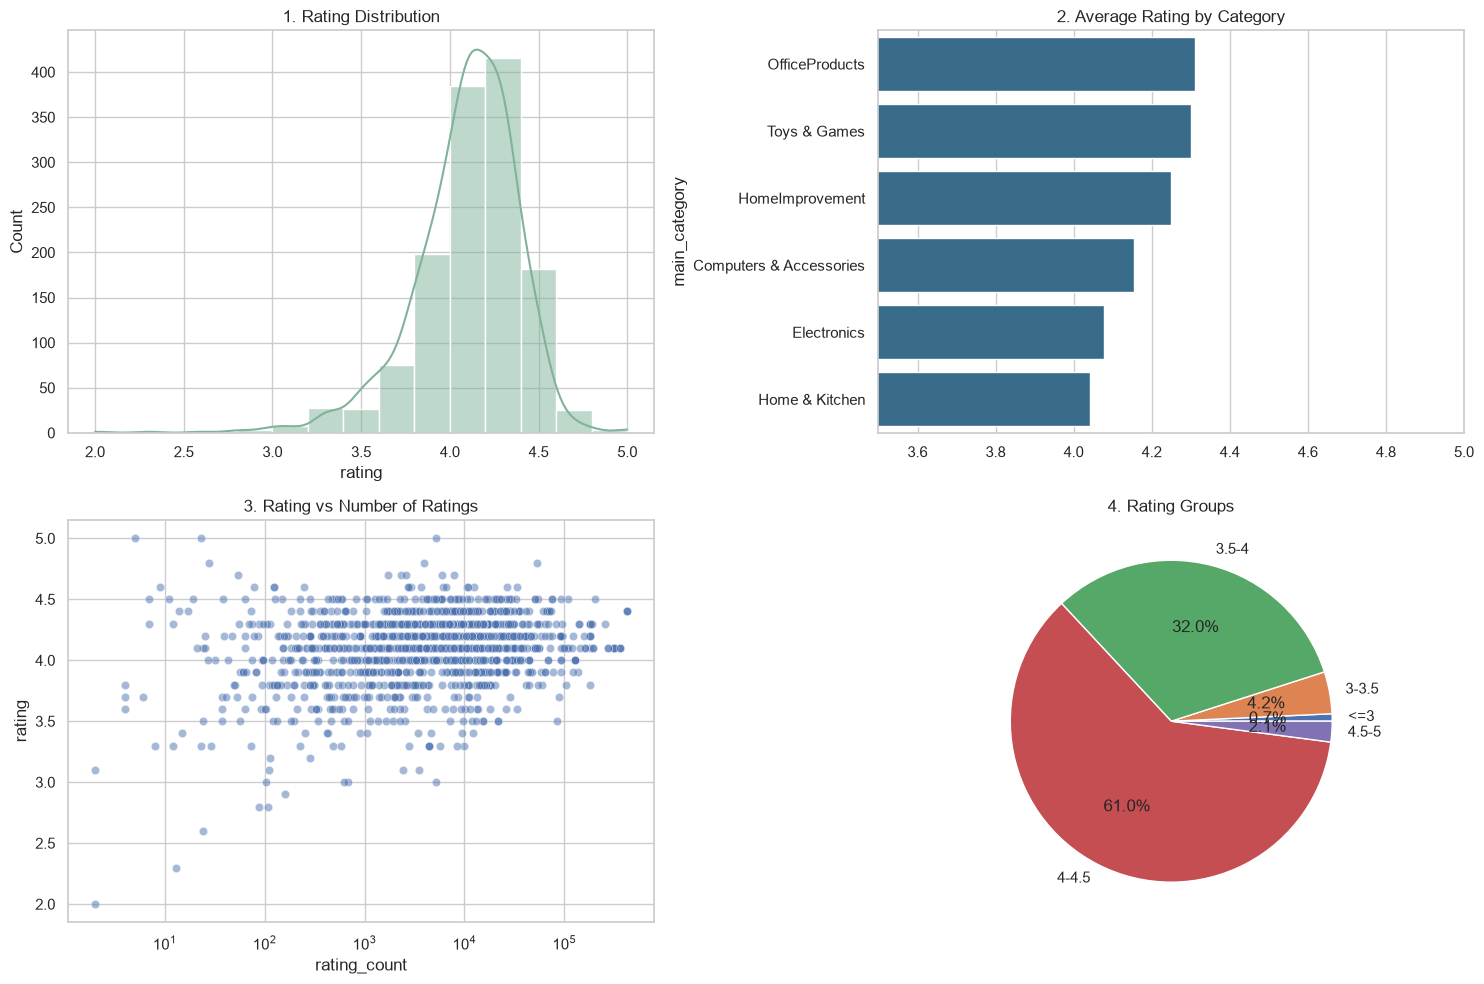

In [18]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(df["rating"], bins=15, kde=True, color="#81b29a", ax=ax[0, 0])
ax[0, 0].set_title("1. Rating Distribution")

r = (df.groupby("main_category")["rating"].mean()
       .sort_values(ascending=False).head(6))
sns.barplot(x=r.values, y=r.index, color="#2a6f97", ax=ax[0, 1])
ax[0, 1].set_xlim(3.5, 5)
ax[0, 1].set_title("2. Average Rating by Category")

sns.scatterplot(data=df, x="rating_count", y="rating", alpha=0.5, ax=ax[1, 0])
ax[1, 0].set_xscale("log")
ax[1, 0].set_title("3. Rating vs Number of Ratings")

buckets = pd.cut(df["rating"], [0, 3, 3.5, 4, 4.5, 5],
                 labels=["<=3", "3-3.5", "3.5-4", "4-4.5", "4.5-5"])
buckets.value_counts().sort_index().plot.pie(autopct="%1.1f%%", ax=ax[1, 1])
ax[1, 1].set_ylabel("")
ax[1, 1].set_title("4. Rating Groups")
plt.tight_layout(); plt.show()

### Observations: Ratings and Popularity
1. **Rating distribution:** Ratings are tightly clustered around 4.1 (mean 4.09, standard deviation 0.30). Very few products are rated below 3.5.
2. **Rating by category:** The three main categories are close: Computers & Accessories (4.15), Electronics (4.08) and Home & Kitchen (4.04). Categories with only 1-2 products, such as Toys & Games, look high or low only because of tiny sample sizes.
3. **Rating vs number of ratings:** There is almost no relationship (correlation about 0.10). Products with a very large number of ratings are not clearly better rated.
4. **Rating groups:** 61% of products fall between 4.0 and 4.5 stars and 32% between 3.5 and 4.0. Only about 5% are below 3.5.

**Insight:** Customer ratings on Amazon are generally positive and similar across categories, so rating alone does not separate good products from average ones.

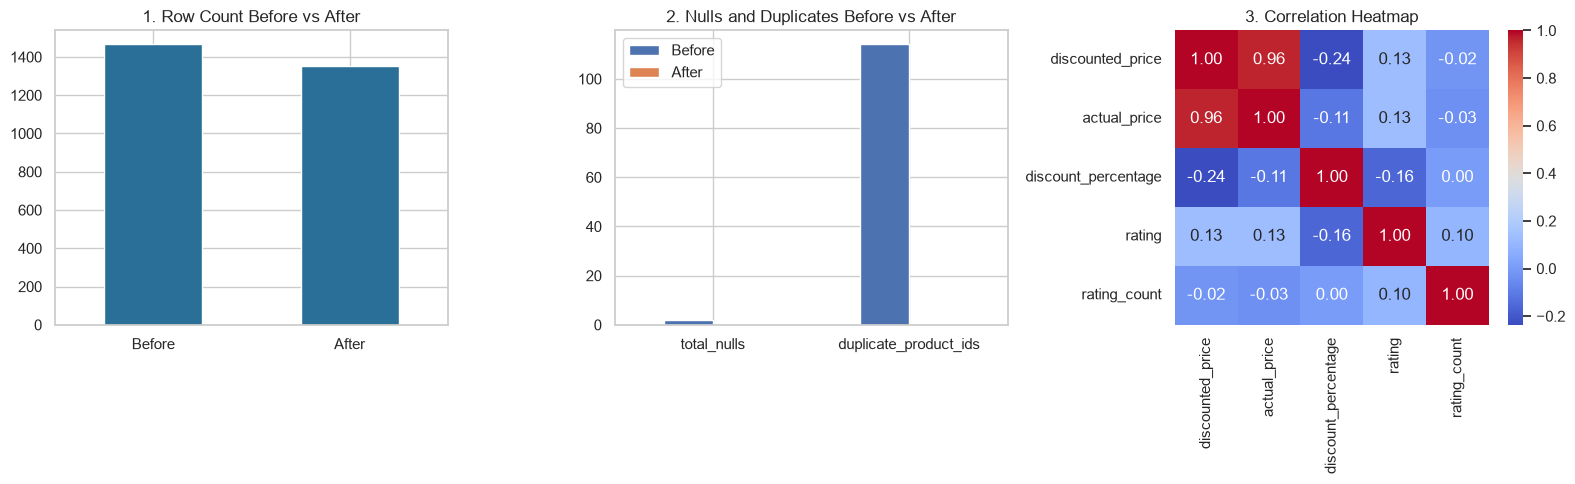

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
cmp = pd.DataFrame({"Before": before, "After": after})

cmp.loc[["rows"]].T.plot.bar(ax=ax[0], legend=False, color="#2a6f97", rot=0)
ax[0].set_title("1. Row Count Before vs After")

cmp.loc[["total_nulls", "duplicate_product_ids"]].plot.bar(ax=ax[1], rot=0)
ax[1].set_title("2. Nulls and Duplicates Before vs After")

sns.heatmap(df[["discounted_price", "actual_price", "discount_percentage",
                "rating", "rating_count"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", ax=ax[2])
ax[2].set_title("3. Correlation Heatmap")
plt.tight_layout(); plt.show()

### Observations: Before vs After Cleaning
1. **Row count:** Rows dropped from 1,465 to 1,351 after removing 114 repeated product IDs.
2. **Quality issues:** Nulls fell from 2 to 0 and duplicate product IDs from 114 to 0. All 5 numeric columns now have correct data types.
3. **Correlation heatmap:** `actual_price` and `discounted_price` are strongly correlated (0.96). Discount percentage has a weak negative correlation with price (about -0.24) and with rating (about -0.16). Rating and number of ratings are only weakly related (about 0.10).

**Insight:** The cleaned dataset is consistent and ready for further analysis. Price columns carry the same information, so only one of them is needed for modelling.

## Conclusion

### What was done
The raw Amazon India dataset (1,465 rows, 16 columns) was cleaned and prepared for analysis:
- Converted price, discount, rating and rating-count columns from text (₹, commas, %) to numeric types
- Filled 3 missing or invalid values with the median, because the data is right-skewed
- Removed 114 repeated product IDs, leaving one row per product (1,351 rows)
- Split the category hierarchy into main, sub and leaf categories
- Validated ratings (1-5), prices and discount percentages
- Checked outliers with the IQR method and kept them, because high prices and large rating counts are genuine premium and popular products
- Saved the final dataset as `amazon_cleaned.csv` (1,351 rows, 20 columns)

### Key findings from the cleaned data
- Electronics, Home & Kitchen and Computers & Accessories account for about 97% of products.
- Prices are right-skewed: the median discounted price is about ₹899 against a mean of about ₹3,305, and Electronics has the highest prices.
- Discounts are heavy, with an average of about 47%. Computers & Accessories and Electronics discount the most.
- Ratings are consistently high (average 4.09), and 61% of products fall between 4.0 and 4.5 stars.
- Discount % and rating have only a weak negative relationship (about -0.16), and rating is almost unrelated to the number of ratings (about 0.10).

### Result
The cleaned dataset is consistent, has correct data types, no missing values and no duplicate products. It is ready for further work such as category-wise pricing analysis, discount strategy analysis and sentiment analysis of customer reviews.

### Limitations
- The dataset has no date or sales column, so number of ratings was used as a proxy for popularity.
- Some categories have only 1-2 products, so their averages should not be compared with the larger categories.